# 03 — Second dataset (Tiny-GenImage), unseen generators & Misinfo test
**KhabarNazar — Image Analysis Module**

Starting point: the ResNet18 trained on AI vs Real in notebook 02 (`models/resnet18_ai_vs_real.pth`).

| Section | Question it answers |
|---|---|
| 1. Cross-dataset test | How well does the AI-vs-Real model work on datasets it has never seen? |
| 2. Unseen-generator experiment | If we train on some AI generators, can the model detect generators it never saw? |
| 3. Stage-2 training | Train on **AI vs Real + Tiny-GenImage together** — the final model |
| 4. Final comparison | Did the second dataset help, and did the model forget the first one? |
| 5. Misinfo per-generator results | How does the final model handle the newest generators on fake-news topics? |

**Tiny-GenImage note:** its fake images are 256×256 while its real images are larger (~470 px).
To stop the model using image scale as a shortcut, every Tiny-GenImage image is first resized so its shorter
side is 256 px, then cropped to 224×224.

**Misinfo-dataset is never used for training** — it is the fully unseen test set.

In [1]:
import json, time, random, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, ConcatDataset
from torchvision import datasets, models, transforms
from tqdm.auto import tqdm
from sklearn.metrics import (accuracy_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
P = ROOT / "data" / "processed"
MODELS = ROOT / "models"
OUTPUTS = ROOT / "outputs"; OUTPUTS.mkdir(exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
BATCH_SIZE = 64
WORKERS = 4
LR = 1e-4            # best learning rate from notebook 02

GPU: NVIDIA RTX A4000


## 0. Data

In [2]:
norm = [transforms.ToTensor(), transforms.Normalize(MEAN, STD)]
# AI vs Real and Misinfo: crop only (same as notebook 02)
crop_train = transforms.Compose([transforms.RandomCrop(224, pad_if_needed=True, padding_mode="reflect"),
                                 transforms.RandomHorizontalFlip(), *norm])
crop_eval = transforms.Compose([transforms.CenterCrop(224), *norm])
# Tiny-GenImage: resize shorter side to 256 first (equalises real/fake scale), then crop
tiny_train = transforms.Compose([transforms.Resize(256), transforms.RandomCrop(224),
                                 transforms.RandomHorizontalFlip(), *norm])
tiny_eval = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), *norm])

aivr_train_view = datasets.ImageFolder(P / "ai_vs_real" / "train", crop_train)
aivr_eval_view  = datasets.ImageFolder(P / "ai_vs_real" / "train", crop_eval)
tiny_train_view = datasets.ImageFolder(P / "tiny_genimage" / "train", tiny_train)
tiny_eval_view  = datasets.ImageFolder(P / "tiny_genimage" / "train", tiny_eval)

TEST_SETS = {
    "AI vs Real (test)":      datasets.ImageFolder(P / "ai_vs_real" / "test", crop_eval),
    "Tiny-GenImage (val)":    datasets.ImageFolder(P / "tiny_genimage" / "val", tiny_eval),
    "Misinfo (unseen)":       datasets.ImageFolder(P / "misinfo" / "test", crop_eval),
}
for ds in [aivr_train_view, tiny_train_view, *TEST_SETS.values()]:
    assert ds.classes == ["fake", "real"], ds.classes
CLASSES = ["fake", "real"]

def group_of(path):
    # generator name stored at the start of the file name in notebook 01, e.g. "Midjourney_000123.jpg"
    return Path(path).name.split("_")[0]

LABELS = {k: np.array(ds.targets) for k, ds in TEST_SETS.items()}
GROUPS = {k: np.array([group_of(p) for p, _ in ds.samples]) for k, ds in TEST_SETS.items()}
for k, ds in TEST_SETS.items():
    print(f"{k:22s} {len(ds):6d} images")
print("Tiny-GenImage groups:", sorted(set(GROUPS["Tiny-GenImage (val)"])))
print("Misinfo groups:      ", sorted(set(GROUPS["Misinfo (unseen)"])))

AI vs Real (test)       12000 images
Tiny-GenImage (val)      7000 images
Misinfo (unseen)         8000 images
Tiny-GenImage groups: [np.str_('ADM'), np.str_('BigGAN'), np.str_('GLIDE'), np.str_('Midjourney'), np.str_('Real'), np.str_('SD15'), np.str_('VQDM'), np.str_('Wukong')]
Misinfo groups:       [np.str_('FLUX1-dev'), np.str_('PixArt-XL-2-1024-MS'), np.str_('SDXL1'), np.str_('imagen3')]


## Helper functions

In [3]:
def make_resnet():
    m = models.resnet18(weights=None)
    m.fc = nn.Linear(m.fc.in_features, 2)
    return m

def load_model(name):
    m = make_resnet()
    m.load_state_dict(torch.load(MODELS / name, map_location="cpu", weights_only=True))
    return m.to(device).eval()

def eval_loader(ds):
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=WORKERS, pin_memory=True)

@torch.no_grad()
def predict(model, ds):
    # returns the probability of class 1 (real) for every image
    model.eval()
    probs = []
    for x, _ in tqdm(eval_loader(ds), leave=False, desc="predict"):
        with torch.amp.autocast("cuda"):
            probs.append(torch.softmax(model(x.to(device)), 1)[:, 1].float().cpu())
    return torch.cat(probs).numpy()

def evaluate_all(model, stage):
    # accuracy + AUC on every test set; stores probabilities in PREDS[stage]
    PREDS[stage] = {}
    row = {"stage": stage}
    for k, ds in TEST_SETS.items():
        p = predict(model, ds)
        PREDS[stage][k] = p
        row[f"{k} acc"] = accuracy_score(LABELS[k], (p >= 0.5).astype(int))
        row[f"{k} AUC"] = roc_auc_score(LABELS[k], p)
    return row

def per_group(stage, key):
    # accuracy per generator, split into fake (detection rate) and real images
    p, y, g = PREDS[stage][key], LABELS[key], GROUPS[key]
    df = pd.DataFrame({"generator": g, "label": np.array(CLASSES)[y], "correct": (p >= 0.5).astype(int) == y})
    return df.pivot_table(index="generator", columns="label", values="correct", aggfunc="mean")

def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, seen = 0.0, 0, 0
    for x, y in tqdm(loader, leave=False, desc="train" if training else "val"):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.set_grad_enabled(training), torch.amp.autocast("cuda"):
            out = model(x)
            loss = criterion(out, y)
        if training:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        total_loss += loss.item() * y.size(0)
        correct += (out.argmax(1) == y).sum().item()
        seen += y.size(0)
    return total_loss / seen, correct / seen

def finetune(train_ds, val_ds, init_weights, epochs, patience=None, save_as=None):
    # continue training from init_weights; keeps the best validation epoch
    torch.manual_seed(SEED)
    model = load_model(init_weights)
    kw = dict(batch_size=BATCH_SIZE, num_workers=WORKERS, pin_memory=True, persistent_workers=WORKERS > 0)
    train_loader = DataLoader(train_ds, shuffle=True, **kw)
    val_loader = DataLoader(val_ds, shuffle=False, **kw)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda")
    criterion = nn.CrossEntropyLoss()
    print(f"train {len(train_ds)} | val {len(val_ds)} | start from {init_weights}")

    history, best_acc, best_epoch, best_state = [], 0.0, 0, None
    for epoch in range(1, epochs + 1):
        start = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, scaler)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        scheduler.step()
        history.append(dict(epoch=epoch, train_loss=tr_loss, train_acc=tr_acc, val_loss=va_loss, val_acc=va_acc))
        print(f"epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | {(time.time() - start) / 60:.1f} min")
        if va_acc > best_acc:
            best_acc, best_epoch = va_acc, epoch
            best_state = copy.deepcopy(model.state_dict())
        elif patience and epoch - best_epoch >= patience:
            print(f"early stopping (no improvement for {patience} epochs)")
            break
    model.load_state_dict(best_state)
    print(f"best val acc {best_acc:.4f} at epoch {best_epoch}")
    if save_as:
        torch.save(best_state, MODELS / save_as)
        info = dict(init=init_weights, lr=LR, best_epoch=best_epoch, best_val_acc=best_acc, history=history)
        (MODELS / save_as.replace(".pth", "_info.json")).write_text(json.dumps(info, indent=2))
        print("saved", MODELS / save_as)
    return model.eval(), history

def plot_history(h, title, file):
    ep = [e["epoch"] for e in h]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
    a1.plot(ep, [e["val_loss"] for e in h], marker="o", label="validation")
    a1.plot(ep, [e["train_loss"] for e in h], "--", label="train")
    a2.plot(ep, [e["val_acc"] for e in h], marker="o", label="validation")
    a2.plot(ep, [e["train_acc"] for e in h], "--", label="train")
    a1.set_title("Loss"); a2.set_title("Accuracy")
    for a in (a1, a2):
        a.set_xlabel("epoch"); a.legend()
    fig.suptitle(title); plt.tight_layout(); plt.savefig(OUTPUTS / file, dpi=120); plt.show()

PREDS, SUMMARY = {}, []

## 1. Cross-dataset test — the AI-vs-Real model on datasets it has never seen

In [4]:
STAGE1 = "Stage 1: AI vs Real only"
stage1_model = load_model("resnet18_ai_vs_real.pth")
SUMMARY.append(evaluate_all(stage1_model, STAGE1))
display(pd.DataFrame(SUMMARY).set_index("stage").round(4))

predict:   0%|          | 0/188 [00:07<?, ?it/s]

predict:   0%|          | 0/110 [00:07<?, ?it/s]

predict:   0%|          | 0/125 [00:07<?, ?it/s]

,AI vs Real (test) acc,AI vs Real (test) AUC,Tiny-GenImage (val) acc,Tiny-GenImage (val) AUC,Misinfo (unseen) acc,Misinfo (unseen) AUC
stage,,,,,,
Stage 1: AI vs Real only,0.9395,0.9854,0.5649,0.5932,0.7476,0.8528


In [5]:
print("Tiny-GenImage validation, per generator (accuracy):")
display(per_group(STAGE1, "Tiny-GenImage (val)").round(3))
print("Misinfo, per generator (fake = detection rate, real = correctly accepted):")
display(per_group(STAGE1, "Misinfo (unseen)").round(3))

Tiny-GenImage validation, per generator (accuracy):


label,fake,real
generator,,
ADM,0.304,NaN
BigGAN,0.206,NaN
GLIDE,0.364,NaN
Midjourney,0.584,NaN
Real,NaN,0.751
SD15,0.474,NaN
VQDM,0.142,NaN
Wukong,0.574,NaN


Misinfo, per generator (fake = detection rate, real = correctly accepted):


label,fake,real
generator,,
FLUX1-dev,0.979,0.640
PixArt-XL-2-1024-MS,0.953,0.644
SDXL1,0.800,0.652
imagen3,0.663,0.650


## 2. Unseen-generator experiment
Fine-tune the Stage-1 model on Tiny-GenImage using **only four generators** (plus an equal number of real images),
then test on **all seven**. Generators never shown in training are marked *unseen*.

train 14400 | val 1600 | start from resnet18_ai_vs_real.pth


train:   0%|          | 0/225 [00:07<?, ?it/s]

val:   0%|          | 0/25 [00:07<?, ?it/s]

epoch  1 | train loss 0.4704 acc 0.7962 | val loss 0.3122 acc 0.8706 | 3.2 min


train:   0%|          | 0/225 [00:00<?, ?it/s]

...

val:   0%|          | 0/25 [00:00<?, ?it/s]

epoch  4 | train loss 0.1390 acc 0.9468 | val loss 0.2291 acc 0.9113 | 0.3 min


train:   0%|          | 0/225 [00:00<?, ?it/s]

val:   0%|          | 0/25 [00:00<?, ?it/s]

epoch  5 | train loss 0.0945 acc 0.9662 | val loss 0.2220 acc 0.9187 | 0.3 min
best val acc 0.9187 at epoch 5
saved E:\FYP\KhabarNazar\image_module\models\resnet18_tiny_seen4.pth


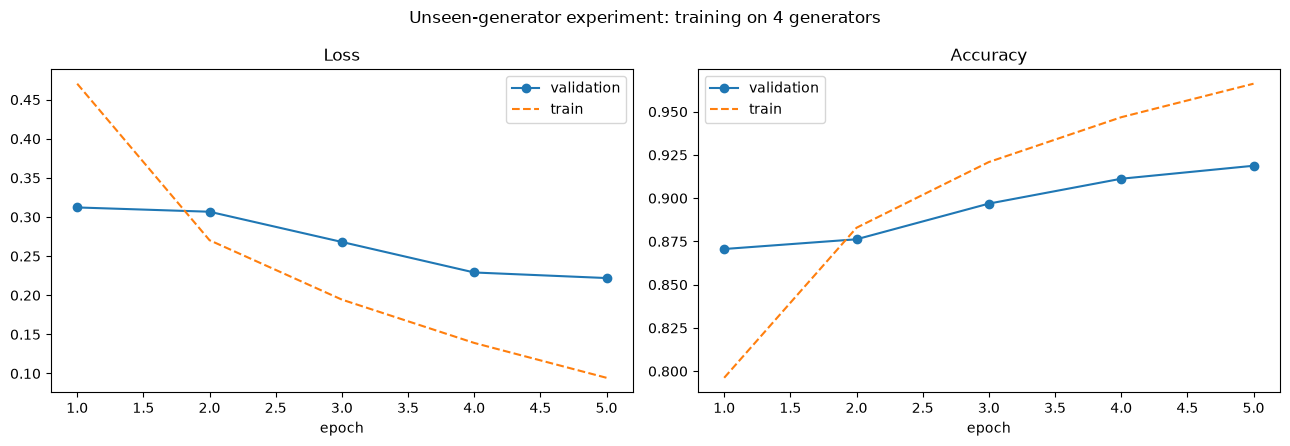

In [6]:
SEEN = ["ADM", "BigGAN", "Midjourney", "SD15"]
UNSEEN = ["GLIDE", "VQDM", "Wukong"]

rng = np.random.RandomState(SEED)
tg = np.array([group_of(p) for p, _ in tiny_train_view.samples])
fake_idx = np.where(np.isin(tg, SEEN))[0]
real_idx = rng.choice(np.where(tg == "Real")[0], len(fake_idx), replace=False)
idx = rng.permutation(np.concatenate([fake_idx, real_idx]))
n_val = len(idx) // 10
seen_train = Subset(tiny_train_view, idx[n_val:].tolist())
seen_val = Subset(tiny_eval_view, idx[:n_val].tolist())

seen_model, seen_hist = finetune(seen_train, seen_val, "resnet18_ai_vs_real.pth", epochs=5,
                                 save_as="resnet18_tiny_seen4.pth")
plot_history(seen_hist, "Unseen-generator experiment: training on 4 generators", "03_seen4_curves.png")

predict:   0%|          | 0/188 [00:07<?, ?it/s]

predict:   0%|          | 0/110 [00:07<?, ?it/s]

predict:   0%|          | 0/125 [00:07<?, ?it/s]

,Stage 1 (AI vs Real only),+ 4 seen generators,type
generator,,,
GLIDE,0.364,0.924,UNSEEN
VQDM,0.142,0.188,UNSEEN
Wukong,0.574,0.854,UNSEEN
Real,0.751,0.919,real images
ADM,0.304,0.834,seen
BigGAN,0.206,0.994,seen
Midjourney,0.584,0.916,seen
SD15,0.474,0.924,seen


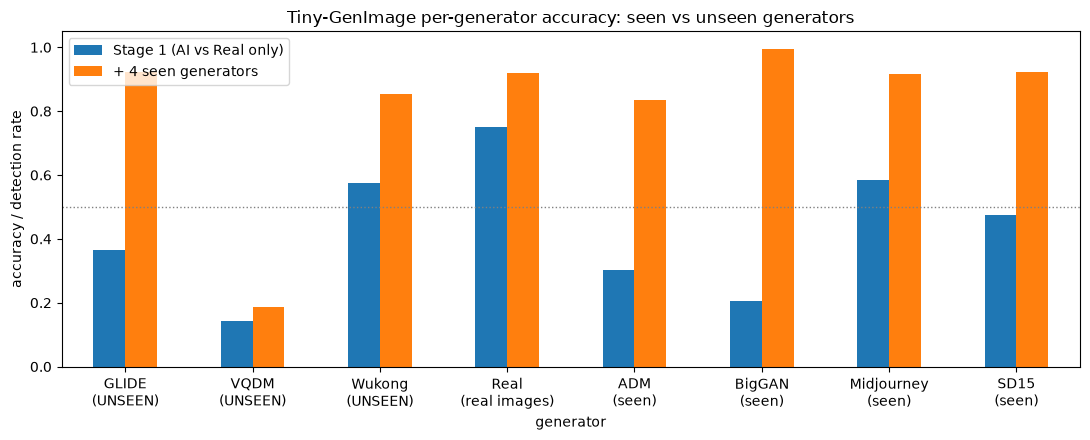

In [7]:
STAGE_SEEN = "Trained on 4 Tiny generators"
evaluate_all(seen_model, STAGE_SEEN)
gen_table = pd.DataFrame({
    "Stage 1 (AI vs Real only)": per_group(STAGE1, "Tiny-GenImage (val)").max(axis=1),
    "+ 4 seen generators": per_group(STAGE_SEEN, "Tiny-GenImage (val)").max(axis=1),
})
gen_table["type"] = ["real images" if g == "Real" else ("seen" if g in SEEN else "UNSEEN") for g in gen_table.index]
gen_table = gen_table.sort_values("type")
display(gen_table.round(3))

ax = gen_table.drop(columns="type").plot.bar(figsize=(11, 4.5), rot=0, ylim=(0, 1.05))
ax.set_xticklabels([f"{g}\n({t})" for g, t in zip(gen_table.index, gen_table["type"])])
ax.set_ylabel("accuracy / detection rate"); ax.axhline(0.5, color="grey", ls=":", lw=1)
plt.title("Tiny-GenImage per-generator accuracy: seen vs unseen generators")
plt.tight_layout(); plt.savefig(OUTPUTS / "03_unseen_generators.png", dpi=120); plt.show()
del seen_model; torch.cuda.empty_cache()

## 3. Stage-2 training — AI vs Real + Tiny-GenImage together
The model is fine-tuned on **all of Tiny-GenImage (28,000)** mixed with **an equal random sample of AI vs Real
(28,000)**. Mixing in the first dataset prevents *catastrophic forgetting* — the model losing what it learned in
Stage 1. Up to 15 epochs with early stopping. Saved as `models/resnet18_final.pth`.

train 50400 | val 5600 | start from resnet18_ai_vs_real.pth


train:   0%|          | 0/788 [00:07<?, ?it/s]

val:   0%|          | 0/88 [00:07<?, ?it/s]

epoch  1 | train loss 0.3594 acc 0.8391 | val loss 0.2963 acc 0.8696 | 7.0 min


train:   0%|          | 0/788 [00:00<?, ?it/s]

...

val:   0%|          | 0/88 [00:00<?, ?it/s]

epoch 14 | train loss 0.0642 acc 0.9759 | val loss 0.2237 acc 0.9275 | 1.4 min


train:   0%|          | 0/788 [00:00<?, ?it/s]

val:   0%|          | 0/88 [00:00<?, ?it/s]

epoch 15 | train loss 0.0640 acc 0.9771 | val loss 0.2218 acc 0.9264 | 1.4 min
best val acc 0.9275 at epoch 14
saved E:\FYP\KhabarNazar\image_module\models\resnet18_final.pth


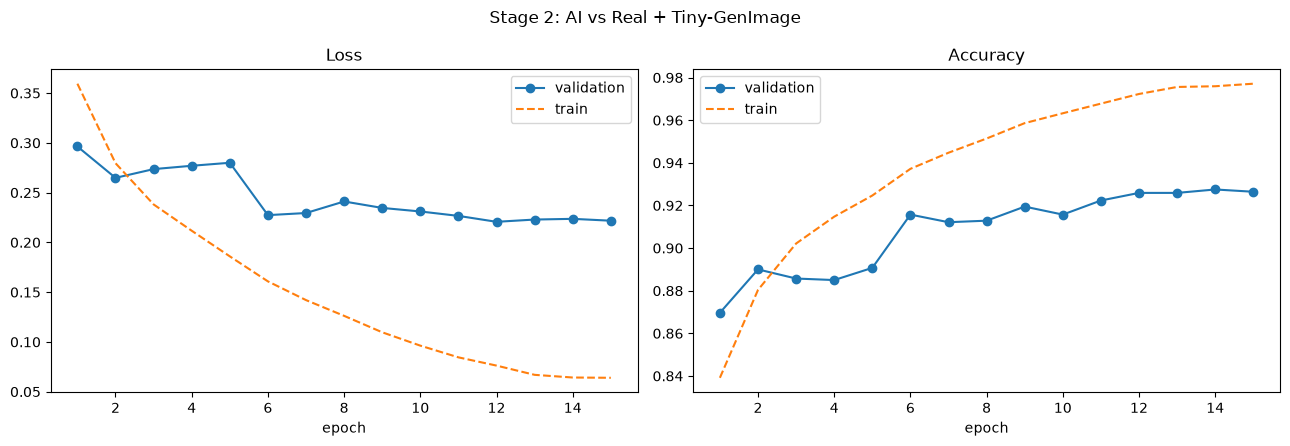

In [8]:
rng = np.random.RandomState(SEED)
tiny_idx = rng.permutation(len(tiny_train_view))
aivr_idx = rng.choice(len(aivr_train_view), len(tiny_train_view), replace=False)
nt, na = len(tiny_idx) // 10, len(aivr_idx) // 10
joint_train = ConcatDataset([Subset(tiny_train_view, tiny_idx[nt:].tolist()),
                             Subset(aivr_train_view, aivr_idx[na:].tolist())])
joint_val = ConcatDataset([Subset(tiny_eval_view, tiny_idx[:nt].tolist()),
                           Subset(aivr_eval_view, aivr_idx[:na].tolist())])

final_model, final_hist = finetune(joint_train, joint_val, "resnet18_ai_vs_real.pth", epochs=15, patience=3,
                                   save_as="resnet18_final.pth")
plot_history(final_hist, "Stage 2: AI vs Real + Tiny-GenImage", "03_stage2_curves.png")

## 4. Final comparison — before vs after the second dataset

In [6]:
   final_model = load_model("resnet18_final.pth")

predict:   0%|          | 0/188 [00:07<?, ?it/s]

predict:   0%|          | 0/110 [00:07<?, ?it/s]

predict:   0%|          | 0/125 [00:07<?, ?it/s]

,AI vs Real (test) acc,AI vs Real (test) AUC,Tiny-GenImage (val) acc,Tiny-GenImage (val) AUC,Misinfo (unseen) acc,Misinfo (unseen) AUC
stage,,,,,,
Stage 1: AI vs Real only,0.9395,0.9854,0.5649,0.5932,0.7476,0.8528
Stage 2: AI vs Real + Tiny-GenImage,0.9383,0.9854,0.9199,0.9757,0.7304,0.8621


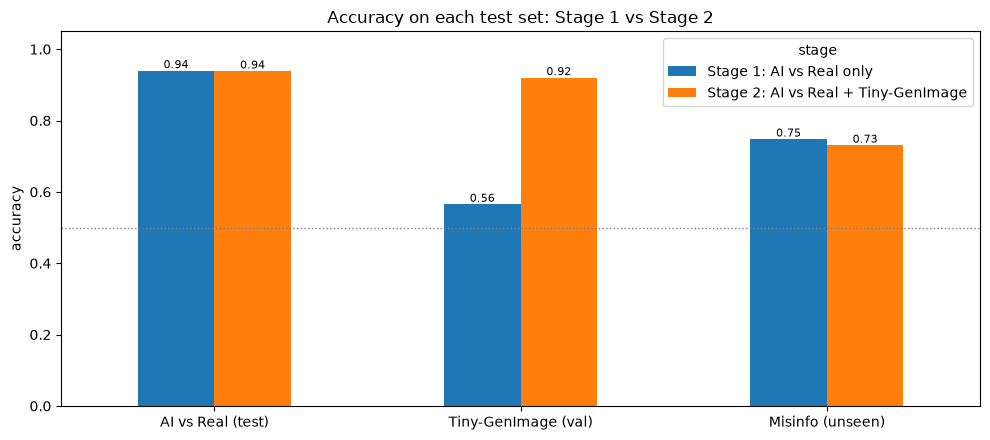

In [7]:
STAGE2 = "Stage 2: AI vs Real + Tiny-GenImage"
SUMMARY.append(evaluate_all(final_model, STAGE2))
summary = pd.DataFrame(SUMMARY).set_index("stage").round(4)
display(summary)
summary.to_csv(OUTPUTS / "03_stage_comparison.csv")

acc = summary[[c for c in summary.columns if c.endswith("acc")]]
acc.columns = [c.replace(" acc", "") for c in acc.columns]
ax = acc.T.plot.bar(figsize=(10, 4.5), rot=0, ylim=(0, 1.05))
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=8)
ax.set_ylabel("accuracy"); ax.axhline(0.5, color="grey", ls=":", lw=1)
plt.title("Accuracy on each test set: Stage 1 vs Stage 2")
plt.tight_layout(); plt.savefig(OUTPUTS / "03_stage_comparison.png", dpi=120); plt.show()

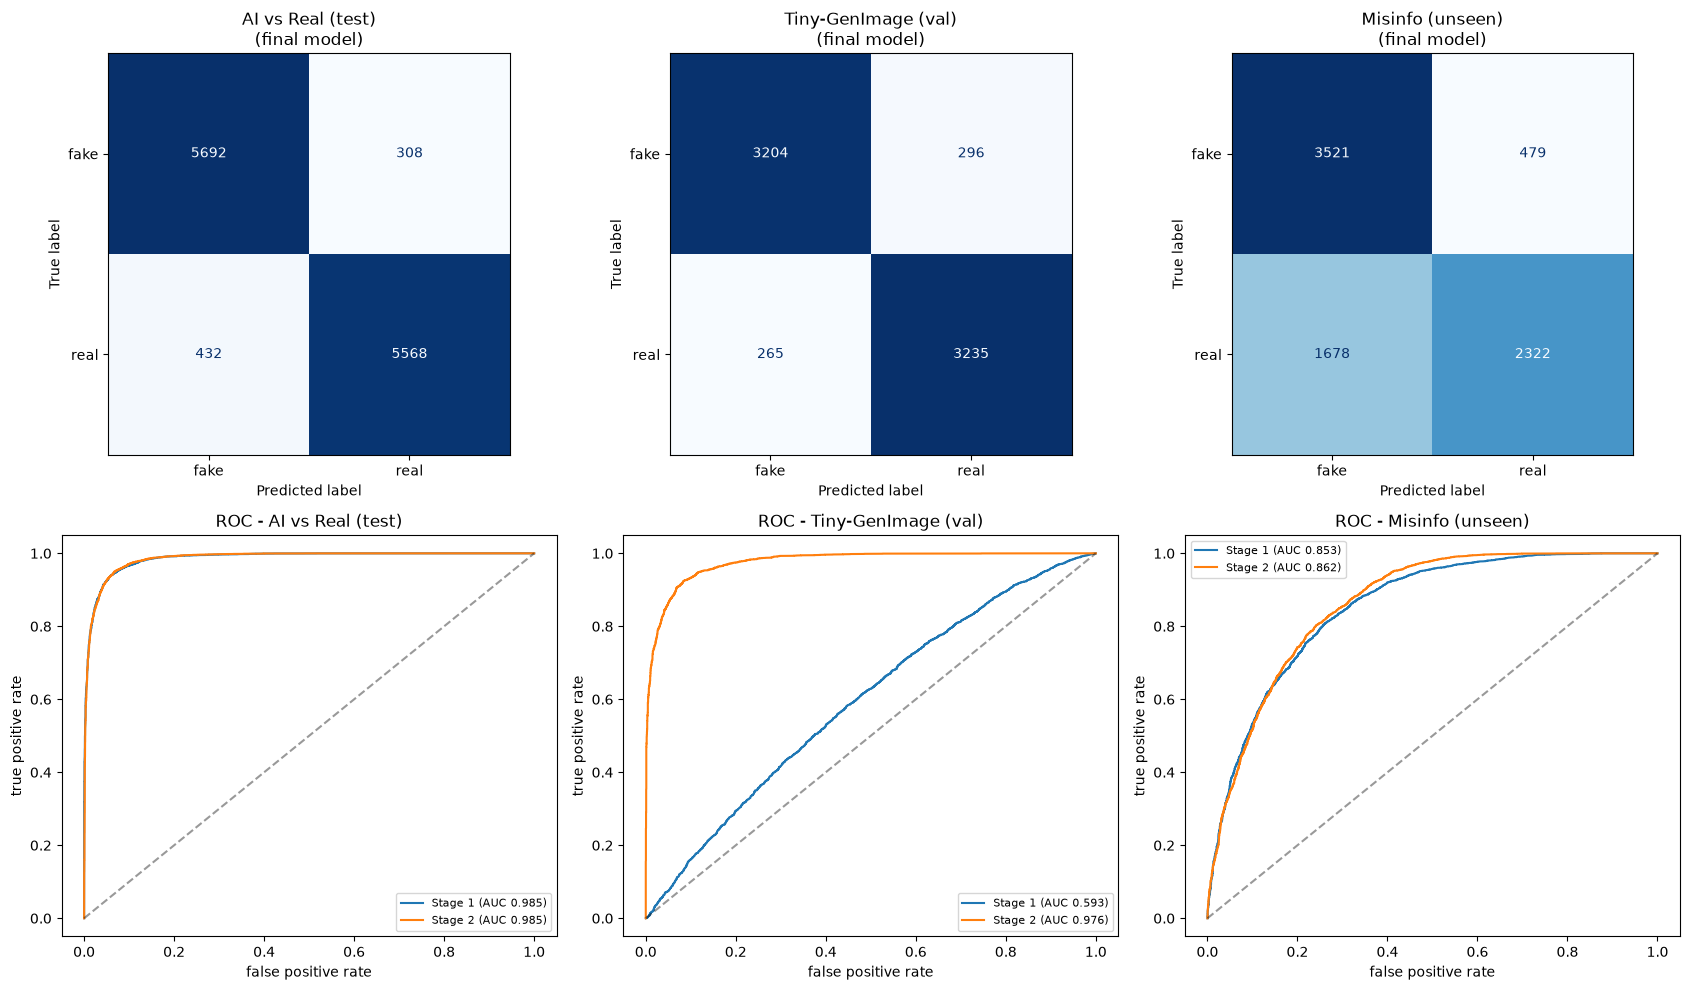

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for i, k in enumerate(TEST_SETS):
    p, y = PREDS[STAGE2][k], LABELS[k]
    ConfusionMatrixDisplay(confusion_matrix(y, (p >= 0.5).astype(int)), display_labels=CLASSES).plot(
        ax=axes[0, i], cmap="Blues", values_format="d", colorbar=False)
    axes[0, i].set_title(f"{k}\n(final model)")
    for stage in [STAGE1, STAGE2]:
        fpr, tpr, _ = roc_curve(y, PREDS[stage][k])
        axes[1, i].plot(fpr, tpr, label=f"{stage.split(':')[0]} (AUC {auc(fpr, tpr):.3f})")
    axes[1, i].plot([0, 1], [0, 1], "k--", alpha=0.4)
    axes[1, i].set_title(f"ROC - {k}"); axes[1, i].set_xlabel("false positive rate")
    axes[1, i].set_ylabel("true positive rate"); axes[1, i].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUTPUTS / "03_final_confusion_roc.png", dpi=120); plt.show()

## 5. Misinfo-dataset per generator (fully unseen, newest generators)

Stage 1        Stage 2       
label                  fake   real    fake   real
generator                                        
FLUX1-dev             0.979  0.640   0.993  0.568
PixArt-XL-2-1024-MS   0.953  0.644   0.990  0.578
SDXL1                 0.800  0.652   0.875  0.593
imagen3               0.663  0.650   0.663  0.583

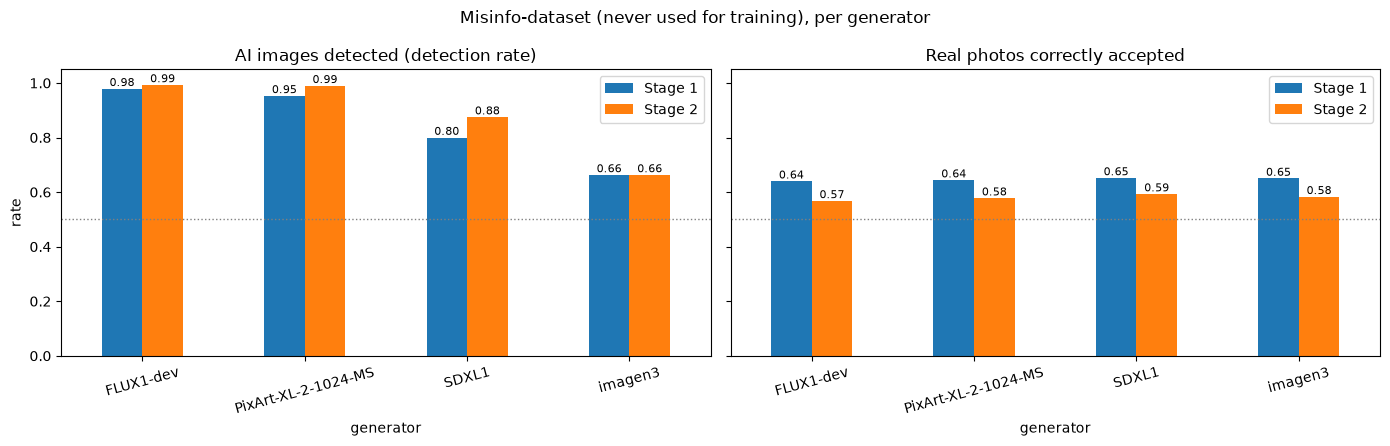

In [11]:
mis = pd.concat({"Stage 1": per_group(STAGE1, "Misinfo (unseen)"),
                 "Stage 2": per_group(STAGE2, "Misinfo (unseen)")}, axis=1)
display(mis.round(3))
mis.to_csv(OUTPUTS / "03_misinfo_per_generator.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, cls, title in [(axes[0], "fake", "AI images detected (detection rate)"),
                       (axes[1], "real", "Real photos correctly accepted")]:
    mis.xs(cls, axis=1, level=1).plot.bar(ax=ax, rot=15, ylim=(0, 1.05))
    ax.set_title(title); ax.set_ylabel("rate"); ax.axhline(0.5, color="grey", ls=":", lw=1)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.2f", fontsize=8)
plt.suptitle("Misinfo-dataset (never used for training), per generator")
plt.tight_layout(); plt.savefig(OUTPUTS / "03_misinfo_per_generator.png", dpi=120); plt.show()

## 6. Summary
- **Section 1** shows how a model trained on one dataset performs on others (cross-dataset generalisation).
- **Section 2** shows the gap between **seen** and **unseen** generators — the central problem in AI-image detection
  (Pelekh, 2025).
- **Sections 3–4** show the effect of adding Tiny-GenImage as a second training dataset, and whether accuracy on
  AI vs Real was kept (no catastrophic forgetting).
- **Section 5** gives the final model's results on the newest generators (FLUX, Imagen 3, PixArt, SDXL) on fake-news
  topics, a dataset it never saw during training.

Final model: `models/resnet18_final.pth`. Next: **04 — Grad-CAM and LIME explanations**.